# 섀넌 엔트로피 실습

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/SuminHan/book-ml/blob/main/slides/v2/ml1/week07/entropy/lab/entropy.ipynb)

놀라움 $-\log_2 p$ 와 그 평균인 엔트로피. 결정 트리의 정보 이득과 글자 압축까지.

- **파트 1**: 놀라움 · 엔트로피 직접 구현 → 0.47, 1.75
- **파트 2**: 정보 이득으로 붓꽃 질문 고르기, `criterion="entropy"`
- **파트 3**: 셜록 홈스 소설의 글자 엔트로피

`None` 으로 비워 둔 `TODO` 줄을 채우고 셀을 차례로 실행하세요.

In [ ]:
import os
from collections import Counter
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

## 파트 1. 놀라움과 엔트로피

$$I(x) = -\log_2 p(x), \qquad H = -\sum_i p_i \log_2 p_i$$

In [ ]:
def surprise(p):
    return None  # TODO: -log2 p

def entropy(probs):
    p = np.asarray(probs, dtype=float)
    p = p[p > 0]                                          # 0 log 0 = 0
    return None  # TODO: average surprise

print("surprise 90%, 10%, 1%:", [round(surprise(p), 2) for p in [0.9, 0.1, 0.01]])
print("Korea vs Brazil:", round(entropy([0.1, 0.9]), 2))
print("weather (1/2, 1/4, 1/8, 1/8):", entropy([0.5, 0.25, 0.125, 0.125]))
ps = np.linspace(0.001, 0.999, 200)
plt.plot(ps, [entropy([p, 1 - p]) for p in ps]); plt.xlabel("p"); plt.ylabel("H (bits)"); plt.show()

**예상 결과**

```
surprise 90%, 10%, 1%: [np.float64(0.15), np.float64(3.32), np.float64(6.64)]
Korea vs Brazil: 0.47
weather (1/2, 1/4, 1/8, 1/8): 1.75
```

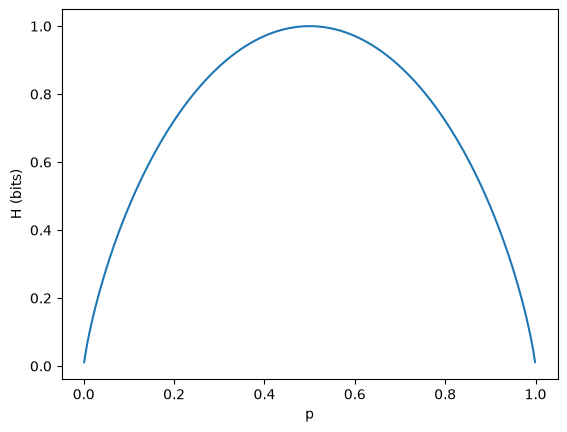

## 파트 2. 정보 이득으로 질문 고르기

정보 이득 = 질문 전 엔트로피 − 질문 후 엔트로피 (양쪽을 개수로 가중 평균).

In [ ]:
os.makedirs("data", exist_ok=True)
if not os.path.exists("data/iris.csv"):
    import urllib.request
    urllib.request.urlretrieve("https://raw.githubusercontent.com/mwaskom/seaborn-data/master/iris.csv", "data/iris.csv")
iris = pd.read_csv("data/iris.csv")
X = iris[["petal_length", "petal_width"]].to_numpy(); y = iris["species"].to_numpy()

def label_entropy(labels):
    _, counts = np.unique(labels, return_counts=True)
    return entropy(counts / counts.sum())

def information_gain(X, y, feature, threshold):
    left = X[:, feature] < threshold
    after = left.mean() * label_entropy(y[left]) + (~left).mean() * label_entropy(y[~left])
    return None  # TODO: before - after

print("start:", round(label_entropy(y), 3))
print("petal length < 2.45:", round(information_gain(X, y, 0, 2.45), 3))
print("petal width  < 1.75:", round(information_gain(X, y, 1, 1.75), 3))

**예상 결과**

```
start: 1.585
petal length < 2.45: 0.918
petal width  < 1.75: 0.686
```

In [ ]:
from sklearn.tree import DecisionTreeClassifier, export_text
for crit in ["gini", "entropy"]:
    t = DecisionTreeClassifier(criterion=crit, max_depth=2, random_state=0).fit(X, y)
    print(crit, "| train accuracy", round(t.score(X, y), 3)); print(export_text(t, feature_names=["petal_length", "petal_width"]))

**예상 결과**

```
gini | train accuracy 0.96
|--- petal_width <= 0.80
|   |--- class: setosa
|--- petal_width >  0.80
|   |--- petal_width <= 1.75
|   |   |--- class: versicolor
|   |--- petal_width >  1.75
|   |   |--- class: virginica

entropy | train accuracy 0.96
|--- petal_width <= 0.80
|   |--- class: setosa
|--- petal_width >  0.80
|   |--- petal_width <= 1.75
|   |   |--- class: versicolor
|   |--- petal_width >  1.75
|   |   |--- class: virginica
```

## 파트 3. 영어 글자의 엔트로피

셜록 홈스 단편집 전체에서 글자(a~z 와 공백) 빈도를 세어 엔트로피를 잰다. 27 가지가 모두 같은 확률이면 $\log_2 27 \approx 4.75$ 비트.

In [ ]:
if not os.path.exists("data/sherlock.txt"):
    import urllib.request
    urllib.request.urlretrieve("https://www.gutenberg.org/cache/epub/1661/pg1661.txt", "data/sherlock.txt")
text = open("data/sherlock.txt", encoding="utf-8").read().lower()
chars = [c for c in text if c.isascii() and (c.isalpha() or c == " ")]
counts = Counter(chars)
probs = np.array(list(counts.values())) / len(chars)
H = None  # TODO: entropy of the letter distribution
print(f"{len(chars):,} characters, {len(counts)} symbols")
print(f"entropy {H:.2f} bits per character  vs  uniform {np.log2(len(counts)):.2f}")
top = counts.most_common(10)
print("most common:", [(repr(c), round(n / len(chars), 3)) for c, n in top])

**예상 결과**

```
545,385 characters, 27 symbols
entropy 4.10 bits per character  vs  uniform 4.75
most common: [("' '", 0.181), ("'e'", 0.101), ("'t'", 0.074), ("'a'", 0.066), ("'o'", 0.064), ("'i'", 0.057), ("'n'", 0.054), ("'h'", 0.054), ("'s'", 0.051), ("'r'", 0.047)]
```

**확인 질문**
1. 파트 1 에서 엔트로피가 가장 큰 p 는? 그때 값은?
2. 파트 2 에서 gini 와 entropy 트리가 고른 질문은 같은가?
3. 파트 3 의 결과로, 글자마다 같은 길이(5비트) 의 부호를 쓰는 것보다 얼마나 줄일 수 있을까? 실제 압축 프로그램이 이보다 더 줄일 수 있는 이유는? (힌트: 'th' 다음엔 'e' 가 잘 온다)
4. (도전) 같은 계산을 한국어 텍스트(한글 음절) 로 하면 엔트로피는 더 클까 작을까? 이유를 생각해 보자.

데이터 출처: Fisher (1936) Iris · Arthur Conan Doyle, The Adventures of Sherlock Holmes (Project Gutenberg #1661, 퍼블릭 도메인).